# WiPER Benchmarking — v13: scoring PLDA e normalizzazione per coorte (open-set)

Stesso protocollo open-set rigoroso di v12 (33 identità di training / 11 di test per fold; 7 note in gallery + 4 sconosciute solo come probe; 4 protocolli; DIR@FAR, AUROC, EER; soglia calibrata **solo** sul training). Risultato v12: Rank-1 sui noti decente (37–44% in `cross`), ma **detection AUROC 0.55–0.62** e DIR@FAR 5% di 4–7%: la similarità coseno non dice se la persona è iscritta. La fase migliorava però la verifica (AUROC 0.65 → 0.71).

## Cosa prova la v13

| # | Idea | Perché |
|---|---|---|
| 1 | **PLDA** (modello a due covarianze) al posto del coseno | Produce un *rapporto di verosimiglianza* stesso-persona / persone-diverse, pensato per la verifica con pochi campioni per identità |
| 2 | **Normalizzazione per coorte**: **T-norm** (statistiche per probe contro una coorte di impostori), **Z-norm** (per elemento di gallery), **S-norm** (media) | Toglie gli offset dipendenti dal singolo probe/gallery (registrazioni "simili a tutti"): spesso alza la detection AUROC |
| 3 | **Selezione annidata** | Fra le 36 configurazioni (3 insiemi di feature × 3 scorer × 4 normalizzazioni) la migliore *per ogni fold* si sceglie con la sola CV interna sulle identità di training: il numero riportato non è gonfiato dalla scelta sul test |

**Scorer:** `cos` (LDA 20 dim + coseno, come v12), `PLDA(LDA)` (PLDA nello spazio LDA a 20 dim), `PLDA(PCA)` (PLDA su PCA a 30 dim, senza uso delle etichette nella riduzione).
**Coorte:** le registrazioni di training del fold (identità diverse da quelle di test): per un probe di azione A contro una gallery di azione G, la T-norm usa le registrazioni di training dell'azione G; la Z-norm usa, per ogni elemento di gallery, quelle dell'azione del probe.

> Caveat: le registrazioni della coorte sono state viste da LDA/PLDA, quindi i loro punteggi sono un po' diversi da quelli fra identità mai viste; la normalizzazione usa solo media e deviazione standard per probe/gallery, ma l'effetto potrebbe non trasferirsi perfettamente. Lo si vede nei risultati e nella calibrazione.

## 1. Imports e configurazione

In [1]:
import os, re, random, time
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import rankdata
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

pd.set_option('display.max_columns', None); pd.set_option('display.width', 250)

CFG = dict(
    seed=42,
    output_folder='./output/',
    sanitization='zscore',            # ampiezze: 'raw' | 'hampel' | 'zscore' | 'iqr'
    exclude_ids=('vuoto',),
    gallery_action='saluto', probe_action='tpose',
    n_subcarriers=52,
    phase_outlier_z=3.0,
    n_folds=4,
    # --- open-set (come v12) ---
    known_fraction=0.64, n_repeats=10,
    far_levels=(0.01, 0.05, 0.10, 0.20),
    calib_far=(0.01, 0.05, 0.10),
    inner_folds=3,
    lda_dim=20,                       # dimensione FISSA dell'embedding LDA (stessa per training interno ed esterno)
    plda_pca_dim=30,                  # dimensione FISSA per PLDA(PCA)
    feature_sets=('amp static', 'ph all', 'amp basic + ph all'),
    scorers=('cos', 'PLDA(LDA)', 'PLDA(PCA)'),
    norms=('none', 'T', 'Z', 'S'),
)

SANITIZATION_DIRS = {
    'raw':    ('CSV', 'raw_amplitudes'),
    'hampel': ('CSV', 'sanitized_amplitudes', 'HF_amplitudes'),
    'zscore': ('CSV', 'sanitized_amplitudes', 'zscore_amplitudes'),
    'iqr':    ('CSV', 'sanitized_amplitudes', 'iqr_amplitudes'),
}
amp_dir = os.path.join(CFG['output_folder'], *SANITIZATION_DIRS[CFG['sanitization']])
csi_dir = os.path.join(CFG['output_folder'], 'CSV', 'csi_matrices')
random.seed(CFG['seed']); np.random.seed(CFG['seed'])

## 2. Caricamento, fase, feature e fold sulle identità

In [2]:
KEY_RE = re.compile(r'^(?P<sid>[^_]+)_(?P<act>[A-Za-z]+)(?P<num>\d+)$')
assert os.path.isdir(amp_dir), f'Cartella non trovata: {amp_dir}'
assert os.path.isdir(csi_dir), f'Cartella non trovata: {csi_dir}'

def load_amp(key):
    return pd.read_csv(os.path.join(amp_dir, key + '.csv')).drop(columns='timestamp', errors='ignore').to_numpy(dtype=np.float64)

def load_csi(key):
    df = pd.read_csv(os.path.join(csi_dir, key + '.csv')).drop(columns='timestamp', errors='ignore')
    return df.to_numpy().astype(str).astype(complex)

def phase_residual(H):
    ph = np.unwrap(np.angle(H), axis=1)
    k = np.arange(H.shape[1]).astype(float); kc = k - k.mean()
    slope = (ph * kc).sum(axis=1) / (kc ** 2).sum()
    icpt = ph.mean(axis=1) - slope * k.mean()
    return ph - (slope[:, None] * k[None, :] + icpt[:, None])

def zscore_fill(M, thr):
    if thr is None: return M
    mu, sd = M.mean(0), M.std(0) + 1e-12
    return pd.DataFrame(M).mask(np.abs((M - mu) / sd) > thr).ffill().bfill().to_numpy()

recs = []
for fname in sorted(os.listdir(amp_dir)):
    if not fname.endswith('.csv'): continue
    key = fname[:-4]
    if key.split('_')[0] in CFG['exclude_ids']: continue
    m = KEY_RE.match(key)
    if not m: print('ignorato:', key); continue
    A, H = load_amp(key), load_csi(key)
    assert A.shape == H.shape == (A.shape[0], CFG['n_subcarriers']), f'{key}: forme incoerenti {A.shape} vs {H.shape}'
    recs.append(dict(sid=m.group('sid'), act=m.group('act').lower(), num=int(m.group('num')), rec_id=key,
                     A=A, P=zscore_fill(phase_residual(H), CFG['phase_outlier_z'])))

R = len(recs)
rec_sid = np.array([r['sid'] for r in recs]); rec_act = np.array([r['act'] for r in recs])
GAL, PRB = CFG['gallery_action'], CFG['probe_action']
assert GAL in set(rec_act) and PRB in set(rec_act)
print(f'{R} registrazioni | {len(set(rec_sid))} identità | azioni {sorted(set(map(str, rec_act)))}')

def feature_groups(A, P):
    X = A / (A.mean() + 1e-8)
    return {'static': X.mean(0), 'dyn_std': X.std(0), 'diff': np.abs(np.diff(X, axis=0)).mean(0),
            'ph_static': P.mean(0), 'ph_std': P.std(0), 'ph_diff': np.abs(np.diff(P, axis=0)).mean(0)}

fw = defaultdict(list)
for r in recs:
    for k, v in feature_groups(r['A'], r['P']).items(): fw[k].append(v)
feat = {k: np.stack(v) for k, v in fw.items()}
ALL_SETS = {'amp static': ['static'], 'ph all': ['ph_static', 'ph_std', 'ph_diff'],
            'amp basic + ph all': ['static', 'dyn_std', 'diff', 'ph_static', 'ph_std', 'ph_diff']}
XS = {n: np.concatenate([feat[g] for g in ALL_SETS[n]], axis=1) for n in CFG['feature_sets']}

def natural_key(s): return [int(t) if t.isdigit() else t for t in re.split(r'(\d+)', s)]
all_ids = sorted(set(rec_sid), key=natural_key)
rng = np.random.RandomState(CFG['seed']); perm = rng.permutation(len(all_ids))
fold_ids = [sorted([all_ids[i] for i in chunk], key=natural_key) for chunk in np.array_split(perm, CFG['n_folds'])]
folds = [(np.where(~np.isin(rec_sid, t))[0], np.where(np.isin(rec_sid, t))[0]) for t in fold_ids]
print('Fold (identità test / train):', [(len(t), len(set(rec_sid[tr]))) for t, (tr, _) in zip(fold_ids, folds)])
n_test_ids = len(fold_ids[0]); n_known = int(round(CFG['known_fraction'] * n_test_ids))
print(f'Open-set per fold: {n_known} note (gallery) + {n_test_ids - n_known} sconosciute (solo probe); {CFG["n_repeats"]} partizioni')

440 registrazioni | 44 identità | azioni ['saluto', 'tpose']
Fold (identità test / train): [(11, 33), (11, 33), (11, 33), (11, 33)]
Open-set per fold: 7 note (gallery) + 4 sconosciute (solo probe); 10 partizioni


## 3. Scorer: coseno, PLDA (due covarianze) e normalizzazione per coorte

**PLDA a due covarianze:** `x = μ + y + ε`, `y ~ N(0, B)` (fra identità), `ε ~ N(0, W)` (entro identità). Il punteggio di una coppia è `log p(x₁,x₂ | stessa identità) − log p(x₁,x₂ | identità diverse)` in forma chiusa. `B` si stima come covarianza delle medie di classe meno `W/n`, con autovalori ≥ 0.

Tutto (standardizzazione, LDA/PCA, PLDA) è stimato **solo sulle registrazioni di training** del fold.

In [3]:
class PLDA:
    # modello a due covarianze; punteggio = log-rapporto di verosimiglianza stessa/diversa identità
    def fit(self, X, y):
        X = np.asarray(X, float); d = X.shape[1]
        self.mu = X.mean(0); Xc = X - self.mu
        labels = np.unique(y); N, C = len(Xc), len(labels)
        means, inv_n, Sw = [], [], np.zeros((d, d))
        for c in labels:
            Xi = Xc[y == c]; m = Xi.mean(0); means.append(m); inv_n.append(1.0 / len(Xi)); Dd = Xi - m; Sw += Dd.T @ Dd
        W = Sw / max(N - C, 1); W = W + 1e-6 * np.trace(W) / d * np.eye(d)
        Mm = np.stack(means); Mm = Mm - Mm.mean(0)
        B = Mm.T @ Mm / max(C - 1, 1) - W * np.mean(inv_n)
        lam, V = np.linalg.eigh((B + B.T) / 2); lam = np.maximum(lam, 1e-4 * max(lam.max(), 1e-12)); B = (V * lam) @ V.T
        T = B + W; Lam = np.block([[T, B], [B, T]]); Li = np.linalg.inv(Lam)
        self.Q = np.linalg.inv(T) - Li[:d, :d]; self.P = -Li[:d, d:]
        self.const = -0.5 * np.linalg.slogdet(Lam)[1] + np.linalg.slogdet(T)[1]
        return self
    def score_matrix(self, Xp, Xg):
        Xp = np.asarray(Xp, float) - self.mu; Xg = np.asarray(Xg, float) - self.mu
        qp = np.einsum('ij,jk,ik->i', Xp, self.Q, Xp); qg = np.einsum('ij,jk,ik->i', Xg, self.Q, Xg)
        return 0.5 * qp[:, None] + 0.5 * qg[None, :] + Xp @ self.P @ Xg.T + self.const

def l2(Z): return Z / (np.linalg.norm(Z, axis=1, keepdims=True) + 1e-12)

def all_pair_scores(fs, tr):
    # matrici di punteggio [R, R] (riga = probe, colonna = gallery) per ogni scorer; tutto stimato su 'tr'
    X = XS[fs]; mu, sd = X[tr].mean(0), X[tr].std(0) + 1e-8
    Z = (X - mu) / sd
    n_comp = int(min(CFG['lda_dim'], len(set(rec_sid[tr])) - 1))
    L = LinearDiscriminantAnalysis(solver='eigen', shrinkage='auto', n_components=n_comp).fit(Z[tr], rec_sid[tr]).transform(Z)
    out = {}
    if 'cos' in CFG['scorers']:
        Ln = l2(L); out['cos'] = Ln @ Ln.T
    if 'PLDA(LDA)' in CFG['scorers']:
        out['PLDA(LDA)'] = PLDA().fit(L[tr], rec_sid[tr]).score_matrix(L, L)
    if 'PLDA(PCA)' in CFG['scorers']:
        Pz = PCA(n_components=int(min(CFG['plda_pca_dim'], Z.shape[1], len(tr) - 1)), random_state=0).fit(Z[tr]).transform(Z)
        out['PLDA(PCA)'] = PLDA().fit(Pz[tr], rec_sid[tr]).score_matrix(Pz, Pz)
    return out

PROTO_DEF = {'cross': (GAL, PRB, False), 'cross_rev': (PRB, GAL, False),
             f'same_{GAL}': (GAL, GAL, True), f'same_{PRB}': (PRB, PRB, True)}
PROTOCOLS = list(PROTO_DEF)

def cohort_stats(S, tr):
    # statistiche di impostori: la coorte sono le registrazioni di training (identità diverse da quelle di test)
    st = {}
    for a in (GAL, PRB):
        C = tr[rec_act[tr] == a]; rows, cols = S[:, C], S[C, :]
        st[a] = dict(row_mu=rows.mean(1), row_sd=rows.std(1) + 1e-9, col_mu=cols.mean(0), col_sd=cols.std(0) + 1e-9)
    return st

def apply_norm(S, st, proto, norm):
    g_act, p_act, _ = PROTO_DEF[proto]
    if norm == 'none': return S
    T = (S - st[g_act]['row_mu'][:, None]) / st[g_act]['row_sd'][:, None]      # T-norm: per probe
    Zn = (S - st[p_act]['col_mu'][None, :]) / st[p_act]['col_sd'][None, :]     # Z-norm: per elemento di gallery
    return T if norm == 'T' else (Zn if norm == 'Z' else 0.5 * (T + Zn))

def label(scorer, norm): return scorer if norm == 'none' else f'{scorer}+{norm}'
CONFIGS = [(fs, sc, nm) for fs in CFG['feature_sets'] for sc in CFG['scorers'] for nm in CFG['norms']]
print(len(CONFIGS), 'configurazioni (insieme di feature × scorer × normalizzazione)')

36 configurazioni (insieme di feature × scorer × normalizzazione)


## 4. Punteggi open-set e metriche (come v12)

In [4]:
def open_set_arrays(Sp, test_idx, known_ids, protocol):
    g_act, p_act, loo = PROTO_DEF[protocol]
    p_idx = test_idx[rec_act[test_idx] == p_act]
    g_idx = test_idx[(rec_act[test_idx] == g_act) & np.isin(rec_sid[test_idx], known_ids)]
    sim = Sp[np.ix_(p_idx, g_idx)].copy()
    if loo:
        where = {gi: j for j, gi in enumerate(g_idx)}
        for i, pi in enumerate(p_idx):
            if pi in where: sim[i, where[pi]] = -np.inf
    ids = list(known_ids)
    id_scores = np.stack([sim[:, rec_sid[g_idx] == u].max(axis=1) for u in ids], axis=1)
    best = id_scores.max(axis=1); top_id = np.array(ids)[id_scores.argmax(axis=1)]
    is_known = np.isin(rec_sid[p_idx], known_ids)
    same = rec_sid[p_idx][:, None] == rec_sid[g_idx][None, :]; ok = np.isfinite(sim)
    return {'max': best, 'correct': (top_id == rec_sid[p_idx]) & is_known, 'known': is_known,
            'pos': sim[same & ok], 'neg': sim[~same & ok]}

def pool(list_of_dicts):
    return {k: np.concatenate([d[k] for d in list_of_dicts]) for k in list_of_dicts[0]}

def auc_from_scores(pos, neg):
    if len(pos) == 0 or len(neg) == 0: return np.nan
    r = rankdata(np.concatenate([pos, neg]))
    return float((r[:len(pos)].sum() - len(pos) * (len(pos) + 1) / 2) / (len(pos) * len(neg)))

def eer(pos, neg):
    if len(pos) == 0 or len(neg) == 0: return np.nan
    thr = np.unique(np.concatenate([pos, neg])); ps, ns = np.sort(pos), np.sort(neg)
    frr = np.searchsorted(ps, thr, side='left') / len(ps)
    far = 1.0 - np.searchsorted(ns, thr, side='left') / len(ns)
    i = np.argmin(np.abs(far - frr)); return float(0.5 * (far[i] + frr[i]))

def threshold_for_far(unk_scores, far):
    n = len(unk_scores); k = int(np.floor(far * n))
    return np.sort(unk_scores)[::-1][k] if k < n else -np.inf

def decision_rates(arr, tau):
    s, kn, cor = arr['max'], arr['known'], arr['correct']; acc = s > tau
    return {'FAR': float(acc[~kn].mean()), 'DIR': float((acc & cor)[kn].mean()),
            'wrong_accept': float((acc & ~cor)[kn].mean()), 'reject': float((~acc)[kn].mean())}

def dir_at_far(arr, far):
    return decision_rates(arr, threshold_for_far(arr['max'][~arr['known']], far))

def summarize(arr):
    out = {'rank1_known': float(arr['correct'][arr['known']].mean()), 'n_unknown': int((~arr['known']).sum()),
           'ver_auc': auc_from_scores(arr['pos'], arr['neg']), 'ver_eer': eer(arr['pos'], arr['neg']),
           'det_auc': auc_from_scores(arr['max'][arr['known']], arr['max'][~arr['known']])}
    for f in CFG['far_levels']: out[f'dir_{f}'] = dir_at_far(arr, f)['DIR']
    d5 = dir_at_far(arr, 0.05); out['wrong'] = d5['wrong_accept']; out['reject'] = d5['reject']
    return out

def known_splits(fold, ids_pool, n_known_, n_rep, salt):
    r = np.random.RandomState(CFG['seed'] + 1000 * salt + fold)
    return [list(r.choice(ids_pool, n_known_, replace=False)) for _ in range(n_rep)]

def inner_splits(train_idx, k, seed):
    ids = sorted(set(rec_sid[train_idx]), key=natural_key)
    perm = np.random.RandomState(seed).permutation(len(ids))
    for chunk in np.array_split(perm, k):
        mask = np.isin(rec_sid[train_idx], [ids[i] for i in chunk])
        yield train_idx[~mask], train_idx[mask], sorted(ids[i] for i in chunk)

# --- sanity: embedding casuali ---
_S = l2(np.random.RandomState(0).randn(R, CFG['lda_dim'])); _S = _S @ _S.T; _arrs = []
for f, (tr, te) in enumerate(folds):
    for kn in known_splits(f, fold_ids[f], n_known, CFG['n_repeats'], 0): _arrs.append(open_set_arrays(_S, te, kn, 'cross'))
_a = pool(_arrs)
print(f"sanity (casuale, cross): Rank-1 noti = {100 * _a['correct'][_a['known']].mean():.1f}% (atteso ≈ {100 / n_known:.1f}%), "
      f"AUROC detection = {auc_from_scores(_a['max'][_a['known']], _a['max'][~_a['known']]):.2f} (atteso ≈ 0.5)")

# --- sanity PLDA: su dati generati dal modello, il punteggio deve separare stessa/diversa identità ---
_r = np.random.RandomState(1); _cls = _r.randn(40, 6) * 1.5; _y = np.repeat(np.arange(40), 8); _X = _cls[_y] + _r.randn(len(_y), 6)
_p = PLDA().fit(_X[:200], _y[:200]); _Sm = _p.score_matrix(_X[200:], _X[200:]); _same = _y[200:][:, None] == _y[200:][None, :]
_off = ~np.eye(len(_Sm), dtype=bool)
print(f"sanity PLDA (dati sintetici): AUROC verifica = {auc_from_scores(_Sm[_same & _off], _Sm[~_same & _off]):.2f}")

sanity (casuale, cross): Rank-1 noti = 16.2% (atteso ≈ 14.3%), AUROC detection = 0.50 (atteso ≈ 0.5)
sanity PLDA (dati sintetici): AUROC verifica = 0.93


## 5. Valutazione esterna (test) e interna (calibrazione e selezione), per tutte le configurazioni

In [5]:
t0 = time.time()
outer = {}; inner = {}
for f, (tr, te) in enumerate(folds):
    splits = known_splits(f, fold_ids[f], n_known, CFG['n_repeats'], 0)
    # --- esterno: modello addestrato su tutto il training del fold, valutato sulle 11 identità di test ---
    for fs in CFG['feature_sets']:
        scores = all_pair_scores(fs, tr)
        for sc, S in scores.items():
            st = cohort_stats(S, tr)
            for nm in CFG['norms']:
                for proto in PROTOCOLS:
                    Sp = apply_norm(S, st, proto, nm)
                    outer[((fs, sc, nm), proto, f)] = pool([open_set_arrays(Sp, te, kn, proto) for kn in splits])
    # --- interno: sole identità di training (calibrazione soglia e selezione configurazione) ---
    inner_acc = defaultdict(list)
    for j, (itr, ite, inner_ids) in enumerate(inner_splits(tr, CFG['inner_folds'], CFG['seed'] + f)):
        nk_in = int(round(CFG['known_fraction'] * len(inner_ids)))
        isplits = known_splits(f * 10 + j, inner_ids, nk_in, CFG['n_repeats'], 1)
        for fs in CFG['feature_sets']:
            scores = all_pair_scores(fs, itr)
            for sc, S in scores.items():
                st = cohort_stats(S, itr)
                for nm in CFG['norms']:
                    for proto in PROTOCOLS:
                        Sp = apply_norm(S, st, proto, nm)
                        inner_acc[((fs, sc, nm), proto)] += [open_set_arrays(Sp, ite, kn, proto) for kn in isplits]
    for k, v in inner_acc.items(): inner[(k[0], k[1], f)] = pool(v)
print(f'{time.time() - t0:.0f}s')

# --- ripetizione con embedding casuali (riferimento) ---
rand_outer = {}
for f, (tr, te) in enumerate(folds):
    S = l2(np.random.RandomState(CFG['seed'] + f).randn(R, CFG['lda_dim'])); S = S @ S.T
    for proto in PROTOCOLS:
        rand_outer[(proto, f)] = pool([open_set_arrays(S, te, kn, proto) for kn in known_splits(f, fold_ids[f], n_known, CFG['n_repeats'], 0)])

metrics = {k: summarize(a) for k, a in outer.items()}
inner_det = {k: auc_from_scores(a['max'][a['known']], a['max'][~a['known']]) for k, a in inner.items()}
rand_metrics = {k: summarize(a) for k, a in rand_outer.items()}

def mean_over_folds(cfg, proto, key): return float(np.mean([metrics[(cfg, proto, f)][key] for f in range(len(folds))]))

33s


## 6. Detection AUROC e DIR@FAR 5% per configurazione (media sui fold)

In [6]:
cols = [label(sc, nm) for sc in CFG['scorers'] for nm in CFG['norms']]
def pivot(key, scale=1.0, nd=3):
    rows = []
    for fs in CFG['feature_sets']:
        for proto in PROTOCOLS:
            rows.append({'feature': fs, 'protocollo': proto,
                         **{label(sc, nm): scale * mean_over_folds((fs, sc, nm), proto, key) for sc in CFG['scorers'] for nm in CFG['norms']}})
    return pd.DataFrame(rows).set_index(['feature', 'protocollo']).round(nd)

print('Riferimento casuale: detection AUROC ≈ 0.50, verifica AUROC ≈ 0.50, DIR@5% ≈', round(100 * np.mean([rand_metrics[(p, f)]['dir_0.05'] for p in PROTOCOLS for f in range(len(folds))]), 1), '%')
print('\n=== Detection AUROC (noti contro sconosciuti) ===');  display(pivot('det_auc'))
print('=== DIR@FAR 5% (%) ===');                              display(pivot('dir_0.05', 100, 1))
print('=== Verifica AUROC (stessa contro diversa persona) ==='); display(pivot('ver_auc'))
print('=== Rank-1 sui noti (%) ===');                          display(pivot('rank1_known', 100, 1))

Riferimento casuale: detection AUROC ≈ 0.50, verifica AUROC ≈ 0.50, DIR@5% ≈ 1.1 %

=== Detection AUROC (noti contro sconosciuti) ===


cos  cos+T  cos+Z  cos+S  PLDA(LDA)  PLDA(LDA)+T  PLDA(LDA)+Z  PLDA(LDA)+S  PLDA(PCA)  PLDA(PCA)+T  PLDA(PCA)+Z  PLDA(PCA)+S
feature            protocollo                                                                                                                                 
amp static         cross        0.578  0.596  0.566  0.589      0.567        0.552        0.546        0.547      0.583        0.564        0.555        0.567
                   cross_rev    0.549  0.546  0.569  0.563      0.542        0.520        0.527        0.524      0.553        0.526        0.549        0.537
                   same_saluto  0.662  0.682  0.656  0.679      0.600        0.566        0.578        0.575      0.603        0.568        0.579        0.575
                   same_tpose   0.627  0.636  0.613  0.633      0.560        0.539        0.554        0.546      0.582        0.564        0.572        0.569
ph all             cross        0.594  0.605  0.606  0.609      0.583        0.534        0.556        0.558      0.589        0.554        0.555        0.561
                   cross_rev    0.591  0.606  0.590  0.606      0.565        0.547        0.564        0.567      0.567        0.555        0.557        0.572
                   same_saluto  0.694  0.690  0.687  0.695      0.670        0.603        0.620        0.622      0.674        0.605        0.625        0.638
                   same_tpose   0.618  0.621  0.610  0.627      0.617        0.542        0.573        0.570      0.634        0.555        0.574        0.580
amp basic + ph all cross        0.618  0.610  0.625  0.633      0.611        0.560        0.585        0.586      0.614        0.564        0.595        0.593
                   cross_rev    0.599  0.618  0.612  0.623      0.586        0.561        0.565        0.572      0.566        0.552        0.565        0.573
                   same_saluto  0.695  0.703  0.717  0.717      0.682        0.604        0.614        0.622      0.683        0.607        0.635        0.629
                   same_tpose   0.649  0.649  0.654  0.657      0.636        0.562        0.581        0.582      0.638        0.565        0.592        0.585

=== DIR@FAR 5% (%) ===


cos  cos+T  cos+Z  cos+S  PLDA(LDA)  PLDA(LDA)+T  PLDA(LDA)+Z  PLDA(LDA)+S  PLDA(PCA)  PLDA(PCA)+T  PLDA(PCA)+Z  PLDA(PCA)+S
feature            protocollo                                                                                                                                
amp static         cross         7.0    2.6    3.6    2.4        4.5          4.0          3.1          3.7        3.6          3.8          5.0          4.9
                   cross_rev     4.7    3.1    2.4    3.4        3.3          3.0          2.6          2.4        1.5          4.1          3.0          3.3
                   same_saluto  13.5   15.2   15.3   16.9        8.3          8.7          7.9          8.5        8.0          7.6          7.4          8.9
                   same_tpose    6.9    9.5   10.1   11.4        4.4          4.3          4.4          3.9        4.6          4.4          4.9          5.6
ph all             cross         4.0    6.1    3.4    5.2        4.7          3.3          2.4          3.1        3.9          3.3          1.5          3.1
                   cross_rev     4.4    2.2    1.3    2.4        2.5          1.1          0.8          1.3        2.1          1.6          1.3          1.3
                   same_saluto  20.3    8.1    7.3    9.8        7.1          7.0          8.1          6.8        8.5          6.6          6.4          7.6
                   same_tpose   12.9   10.1   10.1   13.6        9.1          7.9          5.9          6.9       12.8         10.2          9.8         10.8
amp basic + ph all cross         6.6    6.9    5.1    5.9        6.8          4.3          5.0          7.9        5.1          3.1          4.8          5.5
                   cross_rev     5.2    5.7    6.0    5.9        2.6          2.6          1.4          3.1        2.4          1.1          1.7          2.1
                   same_saluto  20.6   12.8   14.8   14.7       12.1          8.6          6.4          8.9       10.2          8.6          9.2          8.1
                   same_tpose    9.2   11.8   11.9   13.4       10.9          8.5          4.6          8.2       11.5          6.8          8.8          8.1

=== Verifica AUROC (stessa contro diversa persona) ===


cos  cos+T  cos+Z  cos+S  PLDA(LDA)  PLDA(LDA)+T  PLDA(LDA)+Z  PLDA(LDA)+S  PLDA(PCA)  PLDA(PCA)+T  PLDA(PCA)+Z  PLDA(PCA)+S
feature            protocollo                                                                                                                                 
amp static         cross        0.653  0.654  0.653  0.655      0.646        0.643        0.643        0.648      0.640        0.639        0.638        0.643
                   cross_rev    0.650  0.650  0.651  0.652      0.643        0.639        0.642        0.645      0.639        0.634        0.639        0.641
                   same_saluto  0.788  0.789  0.790  0.791      0.770        0.768        0.769        0.773      0.745        0.742        0.744        0.749
                   same_tpose   0.718  0.717  0.717  0.718      0.690        0.681        0.682        0.686      0.682        0.676        0.676        0.679
ph all             cross        0.711  0.716  0.718  0.719      0.681        0.687        0.690        0.694      0.680        0.689        0.692        0.696
                   cross_rev    0.712  0.717  0.717  0.719      0.679        0.688        0.689        0.693      0.677        0.692        0.688        0.695
                   same_saluto  0.823  0.831  0.830  0.833      0.771        0.781        0.779        0.785      0.757        0.776        0.773        0.785
                   same_tpose   0.783  0.781  0.781  0.784      0.756        0.753        0.756        0.764      0.748        0.743        0.745        0.754
amp basic + ph all cross        0.696  0.699  0.700  0.700      0.691        0.689        0.703        0.705      0.675        0.676        0.686        0.691
                   cross_rev    0.694  0.697  0.698  0.698      0.687        0.699        0.688        0.702      0.670        0.681        0.675        0.687
                   same_saluto  0.810  0.814  0.814  0.816      0.783        0.795        0.794        0.803      0.776        0.790        0.790        0.800
                   same_tpose   0.759  0.758  0.758  0.760      0.767        0.757        0.759        0.767      0.744        0.735        0.738        0.747

=== Rank-1 sui noti (%) ===


cos  cos+T  cos+Z  cos+S  PLDA(LDA)  PLDA(LDA)+T  PLDA(LDA)+Z  PLDA(LDA)+S  PLDA(PCA)  PLDA(PCA)+T  PLDA(PCA)+Z  PLDA(PCA)+S
feature            protocollo                                                                                                                                
amp static         cross        37.0   37.0   34.1   36.1       31.0         31.0         25.9         29.9       30.1         30.1         29.4         29.7
                   cross_rev    33.1   33.1   35.5   33.6       34.1         34.1         29.0         32.1       30.8         30.8         31.5         32.6
                   same_saluto  54.9   54.9   50.8   53.3       41.4         41.4         41.4         40.6       41.6         41.6         41.2         43.3
                   same_tpose   46.6   46.6   46.1   48.8       34.5         34.5         32.9         33.9       36.1         36.1         29.7         33.9
ph all             cross        39.4   39.4   42.5   42.4       40.4         40.4         32.7         40.4       40.6         40.6         31.7         39.2
                   cross_rev    40.7   40.7   40.5   40.9       39.3         39.3         39.2         39.7       40.3         40.3         35.7         37.9
                   same_saluto  61.1   61.1   58.5   62.6       52.7         52.7         47.7         51.4       53.7         53.7         47.1         52.4
                   same_tpose   52.1   52.1   49.2   52.1       51.1         51.1         44.4         49.8       52.0         52.0         41.1         48.9
amp basic + ph all cross        44.1   44.1   44.1   44.2       40.5         40.5         38.4         41.6       40.4         40.4         37.5         41.9
                   cross_rev    48.3   48.3   45.5   49.1       43.1         43.1         39.8         41.4       43.1         43.1         39.3         43.3
                   same_saluto  62.4   62.4   61.1   62.7       58.6         58.6         52.1         56.3       58.9         58.9         53.2         55.9
                   same_tpose   47.0   47.0   49.6   49.0       48.9         48.9         44.7         49.4       49.6         49.6         43.5         49.3

## 7. Selezione annidata: la configurazione si sceglie con la sola CV interna sul training

In [7]:
sel = {}
for f in range(len(folds)):
    score = {cfg: np.mean([inner_det[(cfg, proto, f)] for proto in PROTOCOLS]) for cfg in CONFIGS}
    sel[f] = max(score, key=score.get)
print('Configurazione scelta per fold (detection AUROC interna media sui 4 protocolli):')
for f in range(len(folds)):
    print(f'  fold {f + 1}: {sel[f][0]} | {label(sel[f][1], sel[f][2])}')

def agg_sel(proto, key):
    v = np.array([metrics[(sel[f], proto, f)][key] for f in range(len(folds))]); return v.mean(), v.std()
def fmt(m, s, pct=True): return f'{100 * m:.1f} ± {100 * s:.1f}' if pct else f'{m:.3f} ± {s:.3f}'

# riferimento: baseline v12 (cos, nessuna normalizzazione) con ph all e la migliore configurazione fissa scelta sul test (ottimistica)
fixed_avg = {cfg: np.mean([mean_over_folds(cfg, p, 'det_auc') for p in PROTOCOLS]) for cfg in CONFIGS}
best_fixed = max(fixed_avg, key=fixed_avg.get)
def agg_cfg(cfg, proto, key):
    v = np.array([metrics[(cfg, proto, f)][key] for f in range(len(folds))]); return v.mean(), v.std()

rows = []
for name, getter in [('SELEZIONE ANNIDATA (onesta)', lambda p, k: agg_sel(p, k)),
                     (f'baseline v12: ph all | cos', lambda p, k: agg_cfg(('ph all', 'cos', 'none'), p, k)),
                     (f'miglior config fissa [{best_fixed[0]} | {label(best_fixed[1], best_fixed[2])}] (ottimistica)', lambda p, k: agg_cfg(best_fixed, p, k))]:
    for proto in PROTOCOLS:
        row = {'metodo': name, 'protocollo': proto, 'Rank-1 noti': fmt(*getter(proto, 'rank1_known'))}
        for fl in CFG['far_levels']: row[f'DIR@FAR {int(100 * fl)}%'] = fmt(*getter(proto, f'dir_{fl}'))
        row['AUROC detection'] = fmt(*getter(proto, 'det_auc'), pct=False)
        row['verifica EER %'] = fmt(*getter(proto, 'ver_eer'))
        row['verifica AUROC'] = fmt(*getter(proto, 'ver_auc'), pct=False)
        rows.append(row)
print('\nValori in % (± deviazione standard fra fold), salvo AUROC.')
display(pd.DataFrame(rows).set_index(['metodo', 'protocollo']))

Configurazione scelta per fold (detection AUROC interna media sui 4 protocolli):
  fold 1: amp basic + ph all | cos+S
  fold 2: amp static | cos+S
  fold 3: amp basic + ph all | cos+S
  fold 4: amp basic + ph all | cos

Valori in % (± deviazione standard fra fold), salvo AUROC.


Rank-1 noti   DIR@FAR 1%   DIR@FAR 5%  DIR@FAR 10%  DIR@FAR 20% AUROC detection verifica EER % verifica AUROC
metodo                                             protocollo                                                                                                               
SELEZIONE ANNIDATA (onesta)                        cross        40.6 ± 7.6    1.9 ± 2.9    4.1 ± 3.8    8.1 ± 4.7   13.4 ± 6.3   0.606 ± 0.059     36.4 ± 3.5  0.683 ± 0.037
                                                   cross_rev    42.5 ± 9.9    1.4 ± 1.9    5.2 ± 6.1   10.4 ± 6.4   16.0 ± 8.8   0.591 ± 0.085     36.6 ± 4.2  0.677 ± 0.046
                                                   same_saluto  61.4 ± 3.4    8.4 ± 7.8   13.9 ± 8.4  23.9 ± 13.2  31.4 ± 14.2   0.671 ± 0.061     26.6 ± 1.3  0.810 ± 0.016
                                                   same_tpose   49.0 ± 4.5    4.4 ± 3.4    7.8 ± 4.7   17.1 ± 5.1   24.6 ± 6.7   0.652 ± 0.020     32.7 ± 4.9  0.748 ± 0.047
baseline v12: ph all | cos                         cross        39.4 ± 5.8    1.1 ± 0.7    4.0 ± 2.3    8.6 ± 2.0   12.4 ± 3.3   0.594 ± 0.054     33.8 ± 1.4  0.711 ± 0.015
                                                   cross_rev    40.7 ± 7.7    2.0 ± 1.4    4.4 ± 2.8    8.1 ± 3.2   14.6 ± 4.0   0.591 ± 0.055     33.6 ± 1.2  0.712 ± 0.013
                                                   same_saluto  61.1 ± 7.3  12.6 ± 13.1  20.3 ± 10.0  26.6 ± 13.7  32.6 ± 16.3   0.694 ± 0.095     26.0 ± 4.2  0.823 ± 0.043
                                                   same_tpose   52.1 ± 6.5    9.1 ± 6.0   12.9 ± 5.6   16.0 ± 5.9   20.9 ± 4.5   0.618 ± 0.016     27.9 ± 1.8  0.783 ± 0.013
miglior config fissa [amp basic + ph all | cos+... cross        44.2 ± 1.7    2.4 ± 2.8    5.9 ± 2.4    9.1 ± 4.8   18.6 ± 4.8   0.633 ± 0.078     34.9 ± 1.3  0.700 ± 0.013
                                                   cross_rev    49.1 ± 2.2    1.9 ± 2.0    5.9 ± 5.7    9.4 ± 6.7   18.4 ± 6.6   0.623 ± 0.051     34.8 ± 1.7  0.698 ± 0.018
                                                   same_saluto  62.7 ± 5.4    5.7 ± 3.2   14.7 ± 5.2   24.6 ± 4.6   39.1 ± 9.5   0.717 ± 0.057     26.6 ± 1.2  0.816 ± 0.018
                                                   same_tpose   49.0 ± 4.5    6.4 ± 6.8   13.4 ± 4.8   21.4 ± 1.7   27.8 ± 2.7   0.657 ± 0.023     31.3 ± 2.5  0.760 ± 0.029

## 8. Soglia calibrata solo sul training: FAR/DIR realizzati (configurazione scelta e baseline)

In [8]:
def calibrated(cfg_by_fold):
    rows = []
    for proto in PROTOCOLS:
        res = {tf: [] for tf in CFG['calib_far']}
        for f in range(len(folds)):
            cfg = cfg_by_fold(f); ia = inner[(cfg, proto, f)]; oa = outer[(cfg, proto, f)]
            for tf in CFG['calib_far']:
                res[tf].append(decision_rates(oa, threshold_for_far(ia['max'][~ia['known']], tf)))
        row = {'protocollo': proto}
        for tf in CFG['calib_far']:
            row[f'obiettivo {int(100 * tf)}%: FAR reale'] = 100 * np.mean([r['FAR'] for r in res[tf]])
            row[f'DIR reale ({int(100 * tf)}%)'] = 100 * np.mean([r['DIR'] for r in res[tf]])
        rows.append(row)
    return pd.DataFrame(rows).set_index('protocollo').round(1)

print('Configurazione scelta per fold (selezione annidata):'); display(calibrated(lambda f: sel[f]))
print('Baseline v12 (ph all | cos):');                          display(calibrated(lambda f: ('ph all', 'cos', 'none')))
print('FAR reale ≈ obiettivo ⇒ la soglia appresa sul training si trasferisce alle identità di test.')

Configurazione scelta per fold (selezione annidata):


,obiettivo 1%: FAR reale,DIR reale (1%),obiettivo 5%: FAR reale,DIR reale (5%),obiettivo 10%: FAR reale,DIR reale (10%)
protocollo,,,,,,
cross,2.4,0.0,4.4,3.1,7.6,4.5
cross_rev,2.4,0.0,6.4,3.1,10.1,5.8
same_saluto,0.4,1.9,4.9,7.1,8.0,13.0
same_tpose,1.1,2.9,5.8,8.1,7.9,12.9


Baseline v12 (ph all | cos):


,obiettivo 1%: FAR reale,DIR reale (1%),obiettivo 5%: FAR reale,DIR reale (5%),obiettivo 10%: FAR reale,DIR reale (10%)
protocollo,,,,,,
cross,0.9,0.6,4.6,2.7,9.0,5.1
cross_rev,0.4,0.9,4.1,3.8,9.5,7.4
same_saluto,0.0,2.0,7.6,11.9,9.4,13.6
same_tpose,0.4,4.1,3.8,8.5,7.8,14.3


FAR reale ≈ obiettivo ⇒ la soglia appresa sul training si trasferisce alle identità di test.


## 9. Curve DIR contro FAR

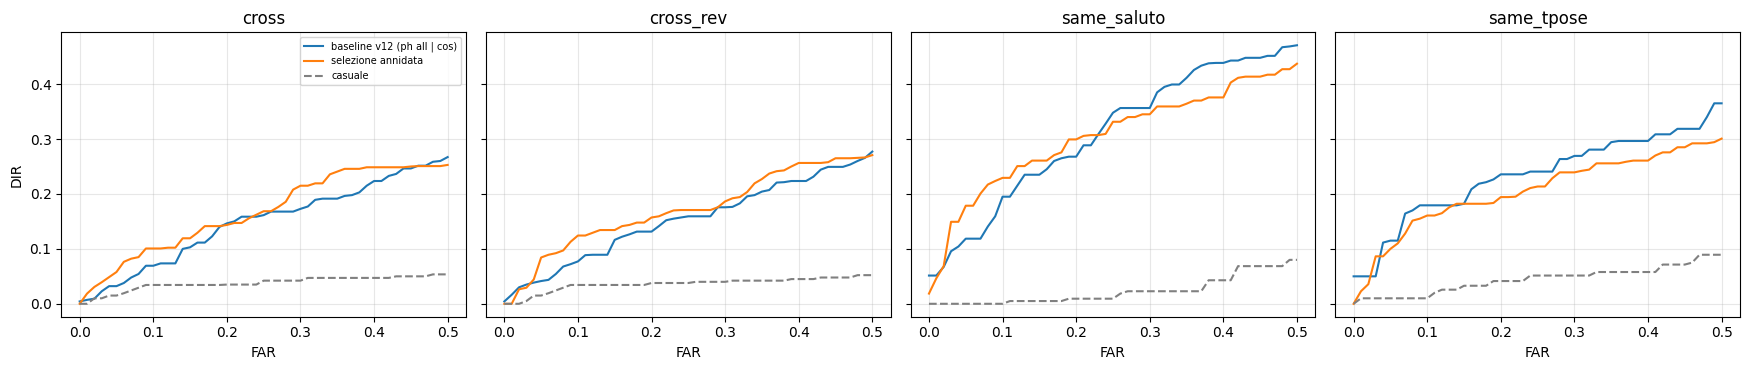

In [9]:
fars = np.linspace(0.0, 0.5, 51)
fig, ax = plt.subplots(1, len(PROTOCOLS), figsize=(4.4 * len(PROTOCOLS), 3.8), sharey=True)
for a, proto in zip(ax, PROTOCOLS):
    curves = {'baseline v12 (ph all | cos)': pool([outer[(('ph all', 'cos', 'none'), proto, f)] for f in range(len(folds))]),
              'selezione annidata': pool([outer[(sel[f], proto, f)] for f in range(len(folds))]),
              'casuale': pool([rand_outer[(proto, f)] for f in range(len(folds))])}
    for name, arr in curves.items():
        a.plot(fars, [dir_at_far(arr, fr)['DIR'] for fr in fars], label=name if proto == PROTOCOLS[0] else None,
               ls='--' if name == 'casuale' else '-', color='gray' if name == 'casuale' else None)
    a.set_title(proto); a.set_xlabel('FAR'); a.grid(alpha=0.3)
ax[0].set_ylabel('DIR'); ax[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

## 10. Come leggere i risultati

* **§6, tabelle pivot:** confronta le colonne `cos`, `cos+T/Z/S`, `PLDA(...)`, `PLDA(...)+T/Z/S`. Se la detection AUROC sale da ≈ 0.6 verso 0.7+ con una normalizzazione o con PLDA, il problema era la calibrazione dei punteggi; se resta ≈ 0.6 ovunque, l'informazione di identità nelle feature non basta per rifiutare gli sconosciuti.
* **§7 (selezione annidata):** è il numero da riportare. La riga "miglior config fissa" è scelta guardando il test e quindi ottimistica: la differenza fra le due misura quanto la scelta gonfierebbe il risultato.
* **§8:** conferma che la soglia scelta sul training si trasferisce (FAR reale ≈ obiettivo) anche con scorer e normalizzazioni diversi. Le normalizzazioni per coorte, se basate su registrazioni già viste dal modello, possono spostare i punteggi dei test: se il FAR reale si discosta molto, è la prima ipotesi.
* **Confronto con v12:** stessi fold, stesse partizioni note/sconosciute e stesse feature: le differenze vengono dallo scoring e dalla normalizzazione.
* Con 4 fold e 4 sconosciuti per fold le deviazioni standard sono ampie; per più stabilità ripeti con altri `seed` o `n_folds=11`.